In [1]:
from torch_geometric.datasets import TUDataset
from torch_geometric.data import DataLoader
import networkx as nx
from torch_geometric.utils.convert import to_networkx
from torch_geometric.utils import from_networkx
import torch
import pickle
import torch.nn.functional as F

In [2]:
dataset = TUDataset(root="TUDataset", name="MUTAG")
with open('datasets/MUTAG_splits.pkl', 'rb') as f:
    split_indices = pickle.load(f)
test_idx = split_indices['test_idx']
test_dataset = [dataset[i] for i in test_idx]

In [23]:
import networkx as nx
import matplotlib.pyplot as plt
import torch
def visualize_mutag_graph(G, pos=None, title=None, ax=None, save_path=None):
    atom_colors = {
        'C': '#FDB813',
        'N': '#3776AB',
        'O': '#FF6961',
        'F': '#ADD8E6',
        'I': '#8A2BE2',
        'Cl': '#228B22',
        'Br': '#FF6347'
    }
    atom_types = ['C', 'N', 'O', 'F', 'I', 'Cl', 'Br']
    node_labels = {}
    node_colors = []
    
    for node in G.nodes():

        node_feature = G.nodes[node].get('x') 
        node_feature = torch.tensor(node_feature)
        if node_feature is not None:
            atom_idx = node_feature.argmax().item()  
            atom = atom_types[atom_idx] 
        else:
            atom = 'C' 

        node_labels[node] = f"{node}_{atom}" 
        node_colors.append(atom_colors.get(atom, '#808080'))

    nodes = list(G.nodes())

    if pos is None:
        pos = nx.spring_layout(G, seed=42)

    if ax is None:
        fig, ax = plt.subplots(figsize=(6, 6))
    
    nx.draw(
        G,
        pos=pos,
        node_size=400,
        font_size=9,
        node_color=node_colors,
        nodelist=nodes,
        font_weight='bold',
        ax=ax
    )

    for node in nodes:
        label = node_labels[node]
        x_pos, y_pos = pos[node]
        ax.text(x_pos, y_pos, label, fontsize=8, ha='center', va='center', color='black', fontweight='bold')

    if title:
        ax.set_title(title, fontsize=10, color='black')
    
    ax.axis('off')

    if save_path:
        plt.savefig(save_path, bbox_inches='tight')
        plt.close(fig)
    else:
        plt.show()


In [24]:
from model.gin import *

device = "cuda" if torch.cuda.is_available() else "cpu"
model = GIN(
        in_channels=dataset.num_features,
        hidden_channels=32,
        out_channels=dataset.num_classes,
        num_layers=5,
    ).to(device)
model.load_state_dict(torch.load("model/GIN_mutag.pth"))
model.eval()

GIN(
  (convs): ModuleList(
    (0): GINConv(nn=Sequential(
      (0): Linear(in_features=7, out_features=64, bias=True)
      (1): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
      (3): Linear(in_features=64, out_features=32, bias=True)
    ))
    (1-4): 4 x GINConv(nn=Sequential(
      (0): Linear(in_features=32, out_features=64, bias=True)
      (1): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
      (3): Linear(in_features=64, out_features=32, bias=True)
    ))
  )
  (batch_norms): ModuleList(
    (0-4): 5 x BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  )
  (mlp): Sequential(
    (0): Linear(in_features=32, out_features=32, bias=True)
    (1): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.5, inplace=False)
    (4): Linear(in_features=32, out_features=2, bias=True)
  )
)

In [3]:
def visualize_mutag_graph(G, pos=None, title=None, ax=None, save_path=None,
                          important_edges=None, important_nodes=None):
    import matplotlib.pyplot as plt
    import torch

    atom_colors = {
        'C': '#FDB813',
        'N': '#3776AB',
        'O': '#FF6961',
        'F': '#ADD8E6',
        'I': '#8A2BE2',
        'Cl': '#228B22',
        'Br': '#FF6347'
    }
    atom_types = ['C', 'N', 'O', 'F', 'I', 'Cl', 'Br']
    node_labels = {}
    node_colors = []
    node_border_colors = []
    node_border_widths = []

    important_nodes = set(important_nodes) if important_nodes else set()
    important_edges = set(important_edges) if important_edges else set()

    for node in G.nodes():
        node_feature = G.nodes[node].get('x')
        node_feature = torch.tensor(node_feature)
        if node_feature is not None:
            atom_idx = node_feature.argmax().item()
            atom = atom_types[atom_idx]
        else:
            atom = 'C'
        node_labels[node] = f"{node}_{atom}"
        node_colors.append(atom_colors.get(atom, '#808080'))

        if f"nL_{node}" in important_nodes:
            node_border_colors.append("black")
            node_border_widths.append(2.5)
        else:
            node_border_colors.append("gray")
            node_border_widths.append(0.5)

    if pos is None:
        pos = nx.spring_layout(G, seed=42)

    if ax is None:
        fig, ax = plt.subplots(figsize=(6, 6))

    nx.draw_networkx_nodes(
        G, pos,
        node_color=node_colors,
        edgecolors=node_border_colors,
        linewidths=node_border_widths,
        node_size=400,
        ax=ax
    )

    edge_colors = []
    edge_widths = []
    for u, v in G.edges():
        edge = tuple(sorted((u, v)))
        if f"n{edge[0]}_n{edge[1]}" in important_edges:
            edge_colors.append("black")
            edge_widths.append(2.5)
        else:
            edge_colors.append("gray")
            edge_widths.append(0.5)

    nx.draw_networkx_edges(
        G, pos,
        width=edge_widths,
        edge_color=edge_colors,
        ax=ax
    )

    nx.draw_networkx_labels(G, pos, labels=node_labels, font_size=8, font_weight='bold', ax=ax)

    if title:
        ax.set_title(title, fontsize=10, color='black')

    ax.axis('off')

    if save_path:
        plt.savefig(save_path, bbox_inches='tight')
        plt.close(fig)
    else:
        plt.show()

### EVALUATION WITH METRICS ###

In [ ]:
import random

def mask(G, rule):
    feature_dim = len(G.nodes[0].get('x')) if G.nodes else 0
    G_maskout = G.copy()
    G_mask = nx.Graph()
    
    for key, cond in rule.items():
        if '_' in key and not key.startswith('nL_'): # edge
            u, v = key.split('_')
            u, v = int(u[1:]), int(v[1:])
            if cond == '>0':
                if not G_mask.has_edge(u, v):
                    if not G_mask.has_node(u) and G.has_node(u):
                        attrs = G.nodes[u]
                        G_mask.add_node(u, **attrs)
                    if not G_mask.has_node(v) and G.has_node(v):
                        attrs = G.nodes[v]
                        G_mask.add_node(v, **attrs)
                    G_mask.add_edge(u, v)
                
                if G_maskout.has_edge(u, v):
                    G_maskout.remove_edge(u, v)
                    
            elif cond == '<=0':
                if not G_maskout.has_edge(u, v):
                    if not G_maskout.has_node(u):
                        new_feature = torch.zeros(feature_dim, dtype=torch.float)
                        node_label = random.choice(range(feature_dim))
                        new_feature[node_label] = 1
                        G_maskout.add_node(u, x=new_feature)
                    if not G_maskout.has_node(v):
                        new_feature = torch.zeros(feature_dim, dtype=torch.float)
                        node_label = random.choice(range(feature_dim))
                        new_feature[node_label] = 1
                        G_maskout.add_node(v, x=new_feature)
                    G_maskout.add_edge(u, v)
                 
                    

        elif key.startswith('nL_'): # node label
            node_id = int(key.split('_')[1])
            if cond != 'None':
                if G_maskout.has_node(node_id):
                    G_maskout.remove_node(node_id)
                    
                if not G_mask.has_node(node_id) and G.has_node(node_id):
                    attrs = G.nodes[node_id]
                    G_mask.add_node(node_id, **attrs)
                    
            else:
                if not G_maskout.has_node(node_id):
                    new_feature = torch.zeros(feature_dim, dtype=torch.float)
                    node_label = random.choice(range(feature_dim))
                    new_feature[node_label] = 1
                    G_maskout.add_node(node_id, x=new_feature)
                    
    return G_maskout, G_mask

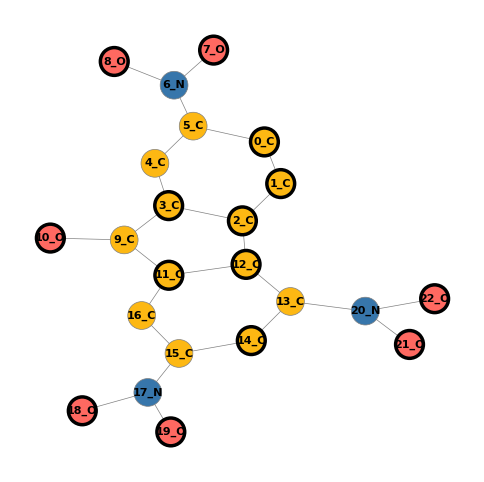

In [5]:
G = to_networkx(dataset[28], to_undirected=True, node_attrs="x")
rule = {'n21_n23': '<=0', 'nL_7': 'O', 'n18_n23': '<=0', 'n2_n23': '<=0', 'nL_18': 'O', 'nL_21': 'O', 'n19_n23': '<=0', 'nL_1': 'C', 'nL_14': 'C', 'nL_2': 'C', 'nL_10': 'O', 'nL_8': 'O', 'nL_25': 'None', 'nL_23': 'None', 'nL_11': 'C', 'nL_0': 'C', 'nL_12': 'C', 'nL_3': 'C', 'nL_22': 'O', 'nL_19': 'O'}
important_nodes = [k for k in rule if k.startswith('nL_')]
important_edges = [k for k in rule if k.startswith('n') and '_n' in k]
G_maskout, G_mask = mask(G, rule)
visualize_mutag_graph(G, pos = nx.kamada_kawai_layout(G) ,important_edges=important_edges, important_nodes=important_nodes)

In [6]:
def evaluate(model, graph, rule, device='cpu'):
    G = to_networkx(graph, to_undirected=True, node_attrs="x")
    l, _ = model(graph.x, graph.edge_index, None)
    p = l.squeeze(0).softmax(dim=-1)
    target_class = torch.argmax(p).item()  
    conf_target = p[target_class].item()
    
    G_maskout, G_mask = mask(G, rule)
    
    g_maskout = from_networkx(G_maskout)
    l_mo, _ = model(g_maskout.x, g_maskout.edge_index, None)
    p_mo = l_mo.squeeze(0).softmax(dim=-1)
    conf_maskout = p_mo[target_class].item()
    
    fidelity = conf_target - conf_maskout
    
    if G_mask.number_of_nodes() < 1:
        return fidelity, 1, 1
    g_mask = from_networkx(G_mask)
    l_m, _ = model(g_mask.x, g_mask.edge_index, None)
    p_m = l_m.squeeze(0).softmax(dim=-1)
    conf_mask = p_m[target_class].item()
    
    inv_fidelity = conf_target - conf_mask

    total_nodes = G.number_of_nodes()
    explained_nodes = G_mask.number_of_nodes()
    sparsity = 1 - (explained_nodes / total_nodes)

    return fidelity, inv_fidelity, sparsity

In [7]:
fi, inv_fi, sparsity = evaluate(model, dataset[28], rule, device=device)
print(f"Fidelity: {fi:.4f}, Inverse Fidelity: {inv_fi:.4f}, Sparsity: {sparsity:.4f}")

NameError: name 'model' is not defined

In [13]:
from hydra import compose, initialize
from omegaconf import OmegaConf

initialize(config_path="config")
config = compose(config_name="config", overrides=["datasets=mutag", "models=gcn", "explainers=tux"])
from model.gnnNets import get_gnnNets
config.models.param = config.models.param[config.datasets.dataset_name]
gcn = get_gnnNets(
    input_dim=dataset.num_node_features,
    output_dim=dataset.num_classes,
    model_config=config.models,
)

gcn_state_dict = torch.load(
    "model/gcn_3l_best.pth"
)["net"]
gcn.load_state_dict(gcn_state_dict)

gcn.eval()




/var/folders/gg/08dxwv590y98p55233w_yc4c0000gn/T/ipykernel_10723/2227768665.py:4: UserWarning: 
The version_base parameter is not specified.
Please specify a compatability version level, or None.
Will assume defaults for version 1.1
  initialize(config_path="config")
/var/folders/gg/08dxwv590y98p55233w_yc4c0000gn/T/ipykernel_10723/2227768665.py:14: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add

GCNNet(
  (readout_layer): GNNPool()
  (convs): ModuleList(
    (0): GCNConv(7, 64)
    (1-2): 2 x GCNConv(64, 64)
  )
  (mlps): ModuleList(
    (0): Linear(in_features=64, out_features=2, bias=True)
  )
)

In [15]:
device = "cuda" if torch.cuda.is_available() else "cpu"
fid, inv_fid, sp = evaluate(gcn, dataset[28], rule, device)
print(f"Fidelity: {fid}, Inverse Fidelity: {inv_fid}, Sparsity: {sp}")

Fidelity: 0.6190173029899597, Inverse Fidelity: -0.3807806968688965, Sparsity: 0.21739130434782605


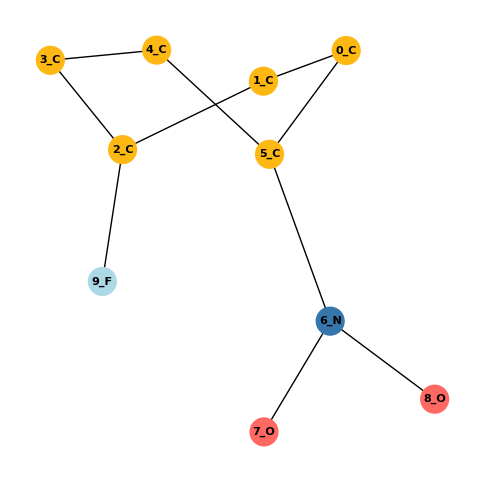

In [295]:
visualize_mutag_graph(G)

In [70]:
import os
import pandas as pd

def generate_population_dataframe(graphs, rules, model, save_dir, mask_fn):
    os.makedirs(save_dir, exist_ok=True)
    
    records = []
    
    for i, data in enumerate(graphs):
        print(f"Processing graph {i}...")
        graph = to_networkx(data, to_undirected=True, node_attrs="x")
        #original graph
        ori_path = os.path.join(save_dir, f"graph_{i}_original.png")
        maskout_path = os.path.join(save_dir, f"graph_{i}_maskout.png")
        mask_path = os.path.join(save_dir, f"graph_{i}_mask.png")
        
        important_edges = [k for k in rules[i] if k.startswith('n') and '_n' in k]
        important_nodes = [k for k in rules[i] if k.startswith('nL_')]
        G_maskout, G_mask = mask_fn(graph, rules[i])
        graph_data = from_networkx(graph)
        prob, prob_maskout, prob_mask, fidelity, inv_fidelity, sparsity = evaluate(model, graph_data, rules[i], device)
        prob = prob.detach().cpu().numpy().astype(float)
        prob_maskout = prob_maskout.detach().cpu().numpy().astype(float)
        prob_mask = prob_mask.detach().cpu().numpy().astype(float)
        
        visualize_mutag_graph(
            graph,
            save_path=ori_path,
            title = f"{prob}",
            important_edges=important_edges,
            important_nodes=important_nodes
        )
       
        visualize_mutag_graph(G_maskout, save_path=maskout_path, title=f"{prob_maskout}")
        visualize_mutag_graph(G_mask, save_path=mask_path, title=f"{prob_mask}")
        
        
        records.append({
            'graph_id': f"{i} Class {data.y.item()}",
            'fidelity': fidelity,
            'inv_fidelity': inv_fidelity,
            'sparsity': sparsity,
            'rule': rules[i],
            'original_graph_path': ori_path,
            'maskout_graph_path': maskout_path,
            'mask_graph_path': mask_path
        })

    return pd.DataFrame(records)

In [51]:
rules = [
    {'n9_n16': '<=0', 'n8_n9': '>0', 'n21_n22': '>0'},
    {'n18_n20': '<=0', 'n10_n19': '>0', 'n2_n7': '>0', 'n3_n4': '>0', 'nL_19': 'C', 'n6_n11': '>0'},
    {'n2_n4': '<=0', 'n1_n7': '<=0', 'n2_n5': '<=0', 'n1_n5': '<=0', 'n3_n6': '<=0', 'n1_n4': '<=0', 'n3_n5': '<=0', 'n1_n3': '<=0', 'n0_n6': '<=0', 'n3_n7': '<=0', 'n0_n9': '<=0', 'n0_n7': '<=0', 'n0_n3': '<=0', 'n4_n8': '<=0', 'n0_n4': '<=0', 'n2_n7': '>0', 'n2_n6': '<=0', 'n4_n7': '<=0', 'n5_n7': '<=0', 'n6_n8': '<=0', 'n6_n10': '<=0', 'n2_n8': '<=0'},
    {'n0_n9': '>0', 'n7_n8': '>0', 'n4_n5': '>0', 'n0_n1': '>0', 'n6_n7': '>0', 'n2_n7': '>0', 'n3_n4': '>0', 'n2_n3': '>0', 'nL_2': 'C', 'n1_n2': '>0', 'nL_4': 'C', 'nL_6': 'C', 'nL_0': 'C', 'nL_5': 'C', 'nL_7': 'C', 'nL_3': 'C', 'nL_9': 'C'},
    {'n2_n16': '>0', 'n10_n15': '>0', 'n9_n10': '>0', 'n3_n9': '>0', 'n15_n16': '>0', 'n2_n3': '>0', 'nL_3': 'C', 'n0_n1': '>0', 'nL_2': 'C', 'n1_n2': '>0', 'n13_n14': '>0', 'nL_15': 'C', 'nL_1': 'C', 'n3_n4': '>0', 'nL_10': 'C', 'n10_n11': '>0', 'nL_14': 'C'},
    {'n6_n11': '>0', 'n10_n11': '>0', 'n3_n6': '>0', 'n7_n8': '>0', 'n4_n16': '<=0', 'n0_n2': '<=0', 'n1_n3': '<=0', 'n3_n5': '<=0', 'n5_n6': '<=0', 'n4_n5': '>0', 'n0_n11': '<=0', 'n6_n7': '>0', 'n4_n10': '<=0', 'n0_n5': '>0', 'n1_n5': '<=0', 'n5_n11': '<=0', 'n8_n11': '<=0', 'n0_n1': '>0', 'n4_n9': '<=0', 'n5_n8': '<=0', 'n1_n10': '<=0', 'n5_n13': '<=0', 'n2_n6': '<=0', 'n4_n11': '<=0', 'n8_n10': '<=0', 'n0_n8': '<=0', 'n7_n9': '<=0', 'n5_n14': '<=0', 'n3_n10': '<=0', 'n1_n2': '>0', 'n0_n4': '<=0', 'n7_n10': '<=0', 'n10_n13': '<=0', 'n0_n9': '<=0', 'n5_n7': '<=0', 'n6_n9': '<=0', 'n3_n4': '>0', 'n5_n9': '<=0', 'n2_n4': '<=0', 'n9_n16': '<=0', 'n1_n9': '<=0', 'n2_n9': '<=0', 'n4_n7': '<=0', 'n3_n9': '<=0', 'n2_n3': '>0', 'nL_6': 'C', 'nL_11': 'C', 'nL_2': 'C', 'nL_12': 'N', 'n2_n11': '<=0', 'nL_7': 'C', 'nL_8': 'C', 'nL_3': 'C', 'nL_4': 'C', 'n4_n8': '<=0', 'nL_5': 'C', 'nL_0': 'C', 'nL_10': 'C', 'n8_n9': '>0', 'n9_n10': '>0', 'nL_9': 'C', 'n2_n8': '<=0', 'n9_n15': '<=0', 'n3_n11': '<=0', 'nL_17': 'None', 'n7_n11': '<=0', 'nL_16': 'None'},
    {'n9_n10': '>0', 'n0_n13': '>0', 'nL_9': 'C', 'n8_n9': '>0', 'n6_n7': '>0', 'n0_n1': '>0', 'n3_n4': '>0'},
    {'n3_n9': '>0', 'n0_n5': '>0', 'n4_n6': '>0', 'n8_n9': '>0', 'n6_n7': '>0', 'n0_n1': '>0', 'n7_n8': '>0', 'nL_10': 'C', 'nL_3': 'C', 'nL_8': 'C', 'n3_n4': '>0', 'n11_n12': '>0', 'nL_9': 'C', 'nL_4': 'C', 'nL_1': 'C', 'n7_n9': '<=0', 'nL_13': 'C'},
    {'n1_n7': '<=0', 'n19_n24': '<=0', 'n1_n24': '<=0', 'n3_n22': '<=0', 'n0_n4': '>0', 'n14_n24': '<=0', 'n23_n24': '<=0', 'n0_n1': '>0', 'n12_n13': '>0', 'nL_2': 'C', 'n8_n16': '<=0', 'n2_n3': '>0', 'n19_n23': '<=0', 'n8_n15': '<=0', 'n6_n22': '<=0', 'nL_5': 'C', 'n22_n23': '<=0', 'n18_n23': '<=0', 'n20_n23': '<=0', 'nL_1': 'C', 'nL_11': 'C'},
    {'n4_n5': '>0', 'n0_n5': '>0', 'n1_n2': '>0', 'nL_1': 'C', 'nL_15': 'C', 'n14_n15': '>0', 'n15_n16': '>0', 'nL_16': 'C', 'nL_2': 'C', 'nL_0': 'C', 'nL_5': 'C', 'n12_n13': '>0', 'n0_n1': '>0', 'nL_13': 'C', 'nL_12': 'C', 'n1_n24': '<=0', 'n1_n25': '<=0', 'n3_n4': '>0', 'nL_14': 'C', 'n13_n14': '>0', 'n17_n24': '<=0', 'n2_n24': '<=0', 'n16_n24': '<=0', 'n12_n25': '<=0', 'nL_4': 'C', 'n2_n25': '<=0', 'n12_n24': '<=0', 'n13_n24': '<=0'},
    {'n1_n10': '<=0', 'n1_n3': '<=0', 'n0_n3': '<=0', 'n2_n10': '<=0', 'n0_n11': '>0', 'n0_n1': '>0', 'n2_n11': '<=0', 'n1_n2': '>0', 'n1_n11': '<=0', 'n3_n11': '<=0', 'n0_n2': '<=0', 'n0_n5': '<=0', 'n1_n8': '<=0', 'n5_n10': '<=0', 'n10_n11': '>0', 'n4_n6': '<=0', 'n5_n11': '<=0', 'n0_n10': '<=0', 'n2_n6': '>0', 'n3_n6': '<=0', 'n3_n10': '>0', 'n5_n6': '>0', 'n1_n9': '<=0', 'n7_n10': '<=0', 'n0_n8': '<=0', 'n7_n11': '<=0', 'n8_n11': '<=0', 'nL_0': 'C', 'n8_n10': '<=0', 'n1_n7': '<=0', 'nL_11': 'C', 'n0_n7': '<=0', 'n10_n12': '<=0', 'n3_n7': '<=0', 'n3_n8': '<=0'},
    {'n2_n4': '<=0', 'n1_n6': '<=0', 'n0_n3': '<=0', 'n0_n6': '<=0', 'n2_n5': '<=0', 'n1_n3': '<=0', 'n5_n8': '<=0', 'n3_n6': '<=0', 'n1_n4': '<=0', 'n0_n7': '<=0', 'n2_n6': '<=0', 'n0_n2': '<=0'},
    {'n1_n10': '>0', 'n8_n9': '>0', 'n2_n3': '>0', 'n3_n5': '<=0', 'n5_n8': '<=0', 'n3_n7': '<=0', 'n0_n10': '<=0', 'n7_n10': '<=0', 'n5_n10': '<=0', 'n1_n7': '<=0', 'n0_n5': '<=0', 'n1_n2': '>0', 'n5_n9': '<=0', 'n9_n10': '>0', 'n3_n8': '<=0', 'n3_n10': '<=0', 'n4_n9': '<=0', 'n4_n5': '>0', 'n1_n5': '<=0', 'n6_n10': '<=0', 'n2_n7': '>0', 'n2_n5': '<=0', 'n7_n8': '>0', 'n0_n2': '<=0', 'n4_n7': '<=0', 'n3_n9': '<=0', 'n0_n4': '<=0', 'n2_n6': '<=0', 'n3_n4': '>0', 'n5_n6': '>0', 'n0_n9': '<=0', 'n3_n6': '<=0', 'n5_n7': '<=0', 'n4_n10': '<=0', 'n1_n6': '<=0', 'n1_n4': '<=0', 'nL_10': 'C', 'nL_4': 'C', 'n3_n13': '<=0', 'n1_n3': '<=0', 'nL_2': 'C', 'nL_1': 'C', 'nL_8': 'C', 'n4_n8': '<=0', 'n0_n7': '<=0', 'nL_11': 'N', 'nL_5': 'C', 'n6_n7': '>0', 'nL_7': 'C', 'nL_6': 'C', 'nL_3': 'C', 'nL_9': 'C', 'nL_0': 'C', 'nL_12': 'O', 'nL_16': 'None', 'nL_15': 'None', 'nL_13': 'O'},
    {'n3_n12': '>0', 'n9_n10': '>0', 'nL_6': 'C', 'n6_n11': '>0', 'n1_n2': '>0', 'n0_n1': '>0', 'n11_n12': '>0', 'n4_n6': '>0', 'nL_0': 'C', 'nL_1': 'C', 'n3_n4': '>0', 'nL_4': 'C', 'nL_2': 'C', 'nL_3': 'C', 'nL_11': 'C', 'n4_n5': '>0', 'n6_n7': '>0', 'nL_10': 'C', 'n10_n11': '>0'},
    {'n10_n19': '>0'},
    {'n0_n8': '>0', 'n0_n1': '>0', 'n2_n6': '>0', 'n4_n5': '>0', 'n1_n2': '>0', 'n7_n8': '>0', 'n3_n4': '>0', 'nL_2': 'C', 'n6_n7': '>0', 'nL_7': 'C', 'nL_6': 'C', 'n2_n3': '>0', 'n5_n6': '>0', 'nL_14': 'None', 'nL_0': 'C', 'nL_1': 'C', 'nL_5': 'N', 'nL_8': 'C', 'n6_n13': '<=0', 'nL_4': 'N'},
    {'n3_n5': '<=0', 'n1_n4': '<=0', 'n0_n6': '<=0', 'n3_n7': '<=0', 'n6_n9': '<=0', 'n0_n5': '<=0', 'n0_n7': '<=0', 'n6_n10': '<=0', 'n4_n11': '<=0', 'n1_n7': '<=0', 'n0_n2': '<=0', 'n2_n5': '<=0', 'n2_n8': '<=0', 'n2_n11': '<=0', 'n6_n11': '<=0', 'n6_n12': '<=0', 'n3_n11': '<=0', 'n3_n9': '<=0', 'n3_n12': '<=0', 'n4_n7': '<=0', 'n1_n5': '<=0', 'n3_n10': '<=0', 'n4_n13': '<=0', 'n6_n13': '<=0', 'n5_n7': '<=0', 'n4_n8': '<=0', 'n4_n9': '<=0', 'n0_n4': '<=0', 'n3_n6': '<=0', 'n2_n10': '<=0', 'n3_n4': '>0', 'n3_n13': '<=0', 'n6_n15': '<=0', 'n4_n12': '<=0', 'n1_n10': '<=0', 'n1_n6': '<=0', 'n2_n14': '<=0', 'n4_n5': '>0', 'n2_n3': '>0', 'n2_n7': '>0', 'n4_n14': '<=0', 'n6_n14': '<=0'},
    {'n3_n12': '>0', 'n8_n9': '>0', 'nL_10': 'C'},
    {'n3_n6': '<=0', 'n3_n7': '<=0', 'n2_n4': '<=0', 'n4_n7': '<=0', 'n2_n5': '<=0', 'n5_n7': '<=0', 'n1_n7': '<=0', 'n0_n4': '<=0', 'n1_n3': '<=0', 'n0_n6': '<=0', 'n1_n4': '<=0', 'n4_n6': '<=0', 'n3_n5': '<=0', 'n0_n5': '<=0', 'n4_n8': '<=0', 'n0_n3': '<=0', 'n3_n9': '<=0', 'n0_n2': '<=0', 'n0_n7': '<=0', 'n6_n9': '<=0', 'n6_n8': '<=0', 'n1_n5': '<=0', 'n5_n8': '<=0', 'n3_n8': '<=0', 'n2_n8': '<=0', 'n2_n6': '<=0', 'n3_n10': '<=0', 'n1_n6': '<=0'}
]

In [71]:
df = generate_population_dataframe(
    test_dataset,
    rules,
    model,
    save_dir='../visualization/mutag',
    mask_fn=mask
)

Processing graph 0...
Processing graph 1...
Processing graph 2...
Processing graph 3...
Processing graph 4...
Processing graph 5...
Processing graph 6...


/var/folders/gg/08dxwv590y98p55233w_yc4c0000gn/T/ipykernel_61519/3424089267.py:26: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  node_feature = torch.tensor(node_feature)


Processing graph 7...
Processing graph 8...
Processing graph 9...
Processing graph 10...
Processing graph 11...
Processing graph 12...
Processing graph 13...
Processing graph 14...
Processing graph 15...
Processing graph 16...
Processing graph 17...
Processing graph 18...


In [80]:
def visualize(df, file_name):
    f = open(file_name, "wt", encoding='utf-8')
    f.write("<html>\n")
    f.write("<body>\n")
    f.write("<h1>Graph Visualization</h1>\n")
    f.write("<table border='1' cellspacing='0' cellpadding='10'>\n")
    for i in range(df.shape[0]):
        row = df.iloc[i]
        f.write("<tr>\n")
        f.write(f"<td>Graph ID: {row['graph_id']}</td>\n")
        f.write(f"<td>Fidelity: {row['fidelity']}</td>\n")
        f.write(f"<td>Inverse Fidelity: {row['inv_fidelity']}</td>\n")
        f.write(f"<td>Sparsity: {row['sparsity']}</td>\n")
        f.write(f"<td>Rule: {row['rule']}</td>\n")
        f.write(f"<td><img src='{row['original_graph_path']}' alt='Original Graph' width='300'></td>\n")
        f.write(f"<td><img src='{row['maskout_graph_path']}' alt='Maskout Graph' width='300'></td>\n")
        f.write(f"<td><img src='{row['mask_graph_path']}' alt='Mask Graph' width='300'></td>\n")
        f.write("</tr>\n")
    f.write("</table>\n")
    
    f.write("</body>\n")
    f.write("</html>\n")
visualize(df, 'experiments/visualization.html')

Prob original: tensor([0.0014, 0.9986], grad_fn=<SqueezeBackward1>)
Prob G\X: tensor([9.9952e-01, 4.8437e-04], grad_fn=<SqueezeBackward1>)
Prob X: tensor([0.9963, 0.0037], grad_fn=<SqueezeBackward1>)
set()


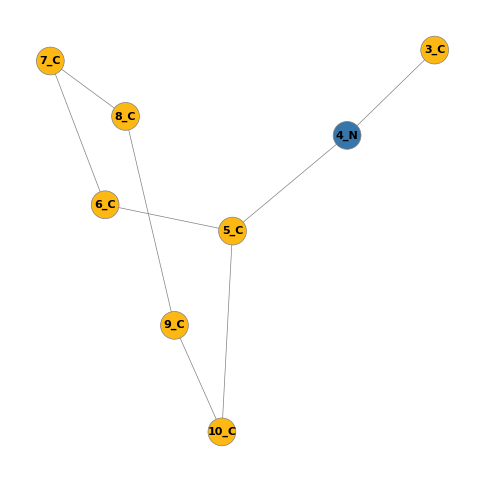

Fidelity: 0.9980914349434897, Inverse Fidelity: 0.9949149205349386, Sparsity: 0.5


In [ ]:
import random

G = to_networkx(dataset[187], to_undirected=True, node_attrs="x")
rule = {'n3_n11': '>0', 'n5_n10': '>0', 'n4_n5': '>0', 'n3_n4': '>0', 'n6_n7': '>0', 'n10_n11': '>0', 'n1_n2': '>0', 'n5_n6': '>0', 'n9_n10': '>0', 'nL_2': 'C', 'n0_n1': '>0', 'nL_1': 'C', 'nL_3': 'C', 'nL_10': 'C', 'nL_11': 'C', 'nL_7': 'C', 'n11_n16': '<=0', 'n7_n8': '>0'}
G_maskout, G_mask = mask(G, rule)
fi, inv_fi, sp = evaluate(model, dataset[187], rule, device=device)
visualize_mutag_graph(G_maskout)
print(f"Fidelity: {fi}, Inverse Fidelity: {inv_fi}, Sparsity: {sp}")

### Edit distance Levenshtein ###

In [101]:
import torch


def graph_to_string(G):
    atom_types = ["C", "N", "O", "F", "I", "Cl", "Br"]
    node_parts = []
    for n in sorted(G.nodes()):
        x = G.nodes[n].get("x")
        if x is not None:
            x_tensor = torch.tensor(x)
            atom_idx = x_tensor.argmax().item()
            label = atom_types[atom_idx]
        else:
            label = "None"
        node_parts.append(label)
    
    edge_parts = []
    max_node = max(G.nodes())
    for i in range(max_node+1):
        for j in range(i, max_node+1):
            if G.has_edge(i, j):
                edge_parts.append("1")
            else:
                edge_parts.append("0")
            

    return "".join(node_parts) + "".join(edge_parts)



In [69]:
def levenshtein_dp(a, b):
    m, n = len(a), len(b)
    dp = [[0]*(n+1) for _ in range(m+1)]

    for i in range(m+1):
        dp[i][0] = i
    for j in range(n+1):
        dp[0][j] = j

    for i in range(1, m+1):
        for j in range(1, n+1):
            if a[i-1] == b[j-1]:
                dp[i][j] = dp[i-1][j-1]
            else:
                dp[i][j] = 1 + min(dp[i-1][j],    
                                   dp[i][j-1],    
                                   dp[i-1][j-1])  

    return dp[m][n]

print(levenshtein_dp("n0=Cn1=Cn2=C", "n1=Cn2=C"))

4


In [102]:

G = to_networkx(dataset[0], to_undirected=True, node_attrs="x")
print(G.number_of_nodes())
graph_str_1 = graph_to_string(G)
G.remove_node(0)
data2 = from_networkx(G)
graph_str_2 = graph_to_string(G)

17


In [105]:
graph_str_1, graph_str_2

('CCCCCCCCCCCCCCNOO010001000000000000100000000000000010000000000000010000100000000110000000000000000000000010000000000100000000010001000010000000100000010000011000000011000',
 'CCCCCCCCCCCCCNOO000000000000000000100000000000000010000000000000010000100000000110000000000000000000000010000000000100000000010001000010000000100000010000011000000011000')

In [106]:
dist = levenshtein_dp(graph_str_2, graph_str_1)
dist

3

In [58]:
print(G.has_edge(0,1))

False
